# **PCA and K-Means Clustering for Customer Segmentation**


## **1. Import Libraries**


In [42]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score


## **2. Load Data**


In [43]:
# Load dataset
df = pd.read_csv('Wholesale customers data.csv')
df.head()


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


In [44]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 440 entries, 0 to 439
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Channel           440 non-null    int64
 1   Region            440 non-null    int64
 2   Fresh             440 non-null    int64
 3   Milk              440 non-null    int64
 4   Grocery           440 non-null    int64
 5   Frozen            440 non-null    int64
 6   Detergents_Paper  440 non-null    int64
 7   Delicassen        440 non-null    int64
dtypes: int64(8)
memory usage: 27.6 KB


## **3. Data Preprocessing & Scaling**


In [45]:
# Drop categorical variables (Channel and Region)
features = df.drop(columns=['Channel', 'Region'])
features.head()


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,12669,9656,7561,214,2674,1338
1,7057,9810,9568,1762,3293,1776
2,6353,8808,7684,2405,3516,7844
3,13265,1196,4221,6404,507,1788
4,22615,5410,7198,3915,1777,5185


In [46]:
# Initialize the scaler
scaler = StandardScaler()

# Fit and transform
scaled_data = pd.DataFrame(
    scaler.fit_transform(features),
    columns=features.columns,
    index=features.index
)
scaled_data.head()


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,0.052933,0.523568,-0.041115,-0.589367,-0.043569,-0.066339
1,-0.391302,0.544458,0.170318,-0.270136,0.086407,0.089151
2,-0.447029,0.408538,-0.028157,-0.137536,0.133232,2.243293
3,0.100111,-0.624020,-0.392977,0.687144,-0.498588,0.093411
4,0.840239,-0.052396,-0.079356,0.173859,-0.231918,1.299347


# Correlation before PCA
There are several predictors having strong correlations with each others.


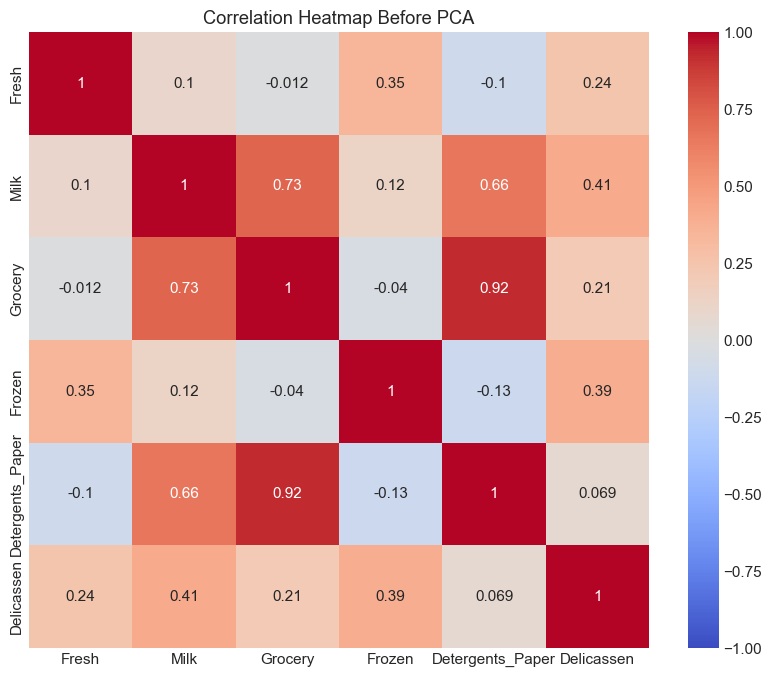

In [47]:
# Compute correlation matrix
correlation_matrix = scaled_data.corr()

plt.figure(figsize=(10, 8))

# Display correlation matrix in a heatmap
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Heatmap Before PCA')
plt.show()


## **4. Dimensionality Reduction with PCA**


In [48]:
# Apply PCA to reduce to 2 components
pca = PCA(n_components=2, random_state=42)
pca.fit(scaled_data)

data_pca = pca.transform(scaled_data)
data_pca = pd.DataFrame(data_pca, columns=['PC1', 'PC2'])
data_pca.head()


,PC1,PC2
0,0.193291,-0.305100
1,0.434420,-0.328413
2,0.811143,0.815096
3,-0.778648,0.652754
4,0.166287,1.271434


In [49]:
# Check explained variance ratio
print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Total explained variance:", sum(pca.explained_variance_ratio_))


Explained variance ratio: [0.44082893 0.283764  ]
Total explained variance: 0.7245929240774498


# Correlation after PCA


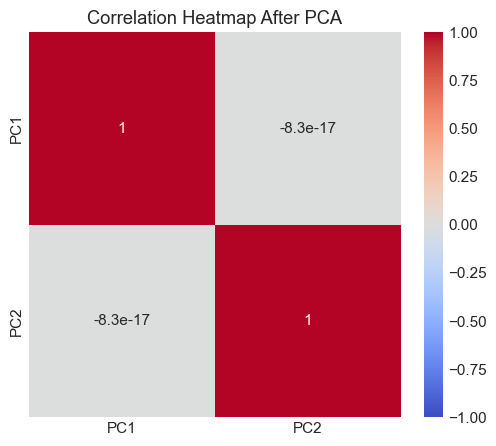

In [50]:
# Compute correlation matrix after PCA
correlation_matrix_pca = data_pca.corr()

plt.figure(figsize=(6, 5))

# Display correlation matrix in a heatmap
sns.heatmap(correlation_matrix_pca, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Heatmap After PCA')
plt.show()


## **5. K-Means Clustering**


In [51]:
X = data_pca.values


### **Elbow Method**


c:\Users\ADMIN\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
c:\Users\ADMIN\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
c:\Users\ADMIN\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
c:\Users\ADMIN\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Window

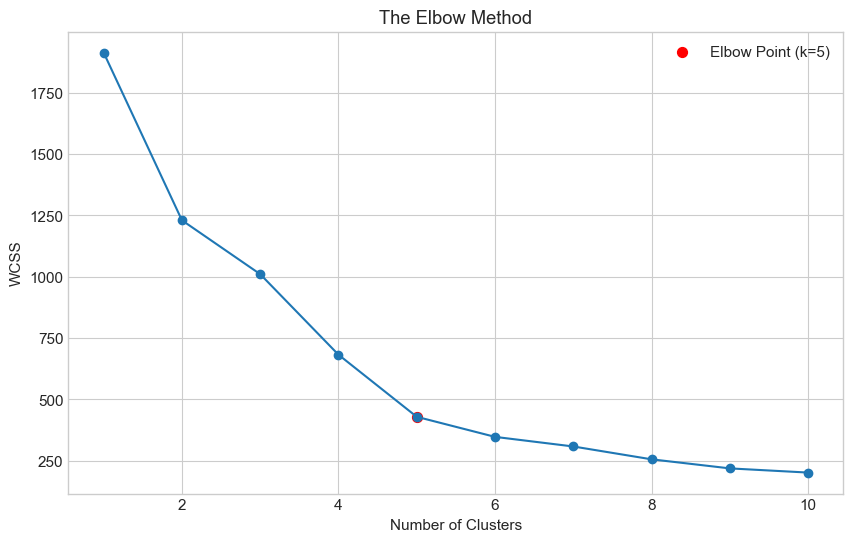

In [52]:
wcss = []
for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, init='k-means++', random_state=42)
    kmeans.fit(X)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(10, 6))
plt.plot(range(1, 11), wcss, marker='o')
plt.scatter(5, wcss[4], s=200, c='red', marker='.', label='Elbow Point (k=5)')
plt.title('The Elbow Method')
plt.xlabel('Number of Clusters')
plt.ylabel('WCSS')
plt.legend()
plt.show()


### **Model Building & Labeling Observations**


In [53]:
# Fit K-Means with chosen k=5
kmeans = KMeans(n_clusters=5, init='k-means++', random_state=42)
labels = kmeans.fit_predict(X)


c:\Users\ADMIN\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


In [54]:
# Assign cluster number and label name back to observations
df_out = df.copy()
df_out['cluster'] = labels + 1

# Map descriptive classification label names based on spending patterns
cluster_names = {
    1: 'Moderate Grocery & Milk Buyers',
    2: 'Fresh & Frozen Food Specialists',
    3: 'Bulk Grocery & Milk Supermarkets',
    4: 'Low-Spending Standard Customers',
    5: 'Ultra-High Spenders / VIP Outliers'
}
df_out['cluster_name'] = df_out['cluster'].map(cluster_names)

print(df_out['cluster_name'].value_counts())
df_out.head(10)


cluster_name
Low-Spending Standard Customers       266
Moderate Grocery & Milk Buyers         93
Fresh & Frozen Food Specialists        68
Bulk Grocery & Milk Supermarkets       10
Ultra-High Spenders / VIP Outliers      3
Name: count, dtype: int64


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,cluster,cluster_name
0,2,3,12669,9656,7561,214,2674,1338,4,Low-Spending Standard Customers
1,2,3,7057,9810,9568,1762,3293,1776,1,Moderate Grocery & Milk Buyers
2,2,3,6353,8808,7684,2405,3516,7844,2,Fresh & Frozen Food Specialists
3,1,3,13265,1196,4221,6404,507,1788,4,Low-Spending Standard Customers
4,2,3,22615,5410,7198,3915,1777,5185,2,Fresh & Frozen Food Specialists
5,2,3,9413,8259,5126,666,1795,1451,4,Low-Spending Standard Customers
6,2,3,12126,3199,6975,480,3140,545,4,Low-Spending Standard Customers
7,2,3,7579,4956,9426,1669,3321,2566,4,Low-Spending Standard Customers
8,1,3,5963,3648,6192,425,1716,750,4,Low-Spending Standard Customers
9,2,3,6006,11093,18881,1159,7425,2098,1,Moderate Grocery & Milk Buyers


### **Cluster Visualization**


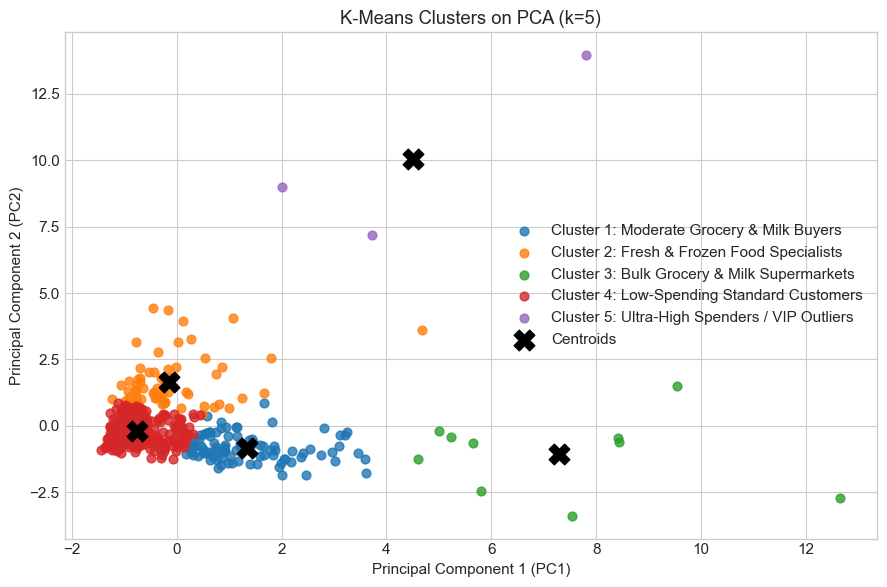

In [55]:
labels = kmeans.labels_
centers = kmeans.cluster_centers_

plt.figure(figsize=(9, 6))
for i in range(kmeans.n_clusters):
    cluster_id = i + 1
    plt.scatter(X[labels == i, 0], X[labels == i, 1],
                s=40, alpha=0.8, label=f'Cluster {cluster_id}: {cluster_names[cluster_id]}')

# Plot centroids
plt.scatter(centers[:, 0], centers[:, 1],
            s=220, marker='X', edgecolor='k', linewidths=1, label='Centroids', c='black')

plt.title('K-Means Clusters on PCA (k=5)')
plt.xlabel('Principal Component 1 (PC1)')
plt.ylabel('Principal Component 2 (PC2)')
plt.legend()
plt.tight_layout()
plt.show()


## **6. Model Evaluation**


In [56]:
sil = silhouette_score(X, labels)
print("Silhouette Score:", round(sil, 3))


Silhouette Score: 0.488
